# CDOM absorption processing with WatercolorLab

This notebook demonstrates a complete CDOM workflow using the bundled WPI example data: salinity-blank correction, input inspection, replicate consistency checks, CDOM absorption retrieval, and exponential fitting.

The notebook is designed to run from either the repository root or the `examples` directory. Paths are resolved relative to the current working directory, so no user-specific path needs to be edited.

**Author:** Bruno Rech

**Last updated:** 7 November 2026

---

#### **Dependencies**

Install the package and its runtime dependencies before running this notebook. See the [installation guide](../docs/getting-started.md) and the [README](../README.md).

In [26]:
import watercolorlab as wcl
import pandas as pd
from pathlib import Path
from matplotlib import pyplot as plt

Paths are resolved in the next cell; the notebook does not change the process working directory.

In [ ]:
# Resolve paths without relying on a local absolute path.
working_dir = Path.cwd()
repo_root = working_dir if (working_dir / 'examples' / 'data' / 'cdom_ex').exists() else working_dir.parent
data_dir = repo_root / 'examples' / 'data'

assert (data_dir / 'cdom_ex').exists(), f'Could not find example data under {data_dir}'
print(f'Using example data from: {data_dir}')

Using example data from: C:\Users\Usuario\Desktop\repos\watercolorlab\examples\data


#### **Open data**

This example processes estuarine samples measured with the WPI UltraPath setup. The samples have variable salinity, so preprocessed salinity curves are supplied as blank references.

The salinity table contains one blank curve per salinity value, with wavelengths in the columns and salinity values in the index.

In [28]:
salinity_curves = pd.read_csv(
    data_dir / 'sal_curve_10cm_interpolated_202604.csv',
    sep=';',
    index_col=0,
)
salinity_curves.head()

,310,311,312,313,314,315,316,317,318,319,...,711,712,713,714,715,716,717,718,719,720
salinity,,,,,,,,,,,,,,,,,,,,,
0.0,0.000176,0.000166,0.000149,0.000111,0.000046,-0.000008,-0.000027,-0.000046,-0.000064,-0.000082,...,-0.002556,-0.002602,-0.002677,-0.002704,-0.002693,-0.002651,-0.002579,-0.002545,-0.002558,-0.002591
0.1,0.000230,0.000218,0.000200,0.000160,0.000093,0.000037,0.000016,-0.000004,-0.000024,-0.000044,...,-0.002526,-0.002572,-0.002646,-0.002672,-0.002662,-0.002620,-0.002547,-0.002514,-0.002526,-0.002558
0.2,0.000285,0.000271,0.000250,0.000209,0.000140,0.000082,0.000059,0.000038,0.000016,-0.000005,...,-0.002497,-0.002541,-0.002614,-0.002640,-0.002630,-0.002588,-0.002516,-0.002483,-0.002494,-0.002526
0.3,0.000339,0.000323,0.000301,0.000258,0.000186,0.000127,0.000103,0.000079,0.000056,0.000034,...,-0.002467,-0.002511,-0.002582,-0.002608,-0.002598,-0.002556,-0.002485,-0.002451,-0.002462,-0.002494
0.4,0.000393,0.000375,0.000351,0.000307,0.000233,0.000171,0.000146,0.000121,0.000097,0.000072,...,-0.002438,-0.002480,-0.002551,-0.002576,-0.002566,-0.002525,-0.002454,-0.002420,-0.002430,-0.002461


Note that each row represents a different salinity, while the columns are the wavelengths. When passing blank curves to the correction, this is the expected format. If a single curve is passed as blank, it must also be in this format.

## Read measured spectra

The bundled filenames encode the sample pattern, sample ID, replicate, and campaign. `read_files` parses those fields into metadata used by the processor.

In [29]:
raw_data = wcl.read_files(
    path=data_dir / 'cdom_ex',
    instrument='wpi',
    format_string='{pattern}{id:d}{rep}_{campaign}',
    sample_pattern='ponto',
    blank_pattern=None,
    decimal='.',
)
raw_data.head()

,pattern,id,rep,campaign,is_blank,is_sample,310,311,312,313,...,711,712,713,714,715,716,717,718,719,720
key,,,,,,,,,,,,,,,,,,,,,
milliq1a_c01,milliq,1,a,c01,False,False,0.000076,0.000078,0.000083,0.000080,...,0.000015,0.000002,-6.666667e-07,-0.000008,-0.000019,-0.000029,-0.000038,-0.000033,-0.000012,0.000004
milliq1b_c01,milliq,1,b,c01,False,False,0.001625,0.001628,0.001616,0.001621,...,-0.000954,-0.000969,-9.666667e-04,-0.000948,-0.000918,-0.000902,-0.000900,-0.000907,-0.000924,-0.000913
milliq1c_c01,milliq,1,c,c01,False,False,0.001625,0.001616,0.001601,0.001607,...,-0.001509,-0.001531,-1.558667e-03,-0.001555,-0.001529,-0.001526,-0.001543,-0.001536,-0.001499,-0.001445
milliq2b_c01,milliq,2,b,c01,False,False,0.000088,0.000104,0.000119,0.000111,...,0.000393,0.000364,3.266667e-04,0.000332,0.000369,0.000360,0.000308,0.000277,0.000272,0.000292
milliq3a_c01,milliq,3,a,c01,False,False,0.000744,0.000742,0.000723,0.000707,...,0.001777,0.001765,1.772000e-03,0.001797,0.001835,0.001833,0.001793,0.001735,0.001657,0.001642


**Tip:** inspect the function contract with `help(wcl.read_files)` or consult the API documentation.

The `format_string` must match the filename convention and include the fields needed by the workflow, especially `pattern` and `id`. A clearer convention for new datasets is `{site}_{pattern}_{id}_{replicate}`.

The reader reports missing values because one bundled measurement is incomplete at shorter wavelengths. We remove that known problematic row before creating the `Spectra` object; for new datasets, investigate missing values before removing any measurements.

In [30]:
raw_data = raw_data.dropna(axis=0)
raw_data.tail(5)

,pattern,id,rep,campaign,is_blank,is_sample,310,311,312,313,...,711,712,713,714,715,716,717,718,719,720
key,,,,,,,,,,,,,,,,,,,,,
ponto05b_c01,ponto,5,b,c01,False,True,2.006897,1.990448,1.973862,1.956830,...,0.019401,0.019363,0.019349,0.019368,0.019411,0.019436,0.019442,0.019473,0.019531,0.019613
ponto05c_c01,ponto,5,c,c01,False,True,2.009500,1.992697,1.975834,1.958781,...,0.019273,0.019236,0.019221,0.019237,0.019274,0.019307,0.019334,0.019383,0.019457,0.019536
ponto06a_c01,ponto,6,a,c01,False,True,1.917947,1.900466,1.882711,1.864468,...,0.017444,0.017428,0.017450,0.017486,0.017533,0.017546,0.017527,0.017558,0.017649,0.017742
ponto06b_c01,ponto,6,b,c01,False,True,1.930514,1.913600,1.896086,1.878309,...,0.016605,0.016585,0.016586,0.016615,0.016665,0.016674,0.016645,0.016675,0.016774,0.016875
ponto06c_c01,ponto,6,c,c01,False,True,1.938146,1.921424,1.904473,1.886524,...,0.016687,0.016671,0.016664,0.016685,0.016727,0.016729,0.016696,0.016717,0.016801,0.016885


Above you can see if the format string separated the attributes properly. See that the format string is used as a key to retrieve important attributes from the file names, and these attributes are divided in columns.

#### **Check consistency**

Now that we have the salinity curves and the data properly configured, we can create our object of interest, called `Spectra`:

In [33]:
spectra = wcl.Spectra(raw_data)
print(spectra)

Object Spectra with 24 observations and 411 wavelengths


The example contains three measurements per station. The consistency check helps identify replicate curves that should be reviewed before averaging them during CDOM processing.

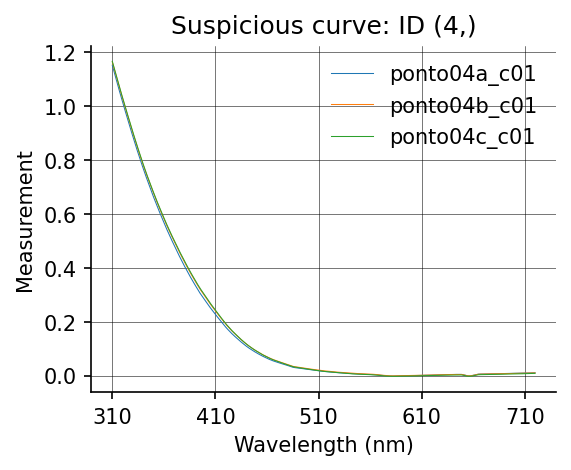

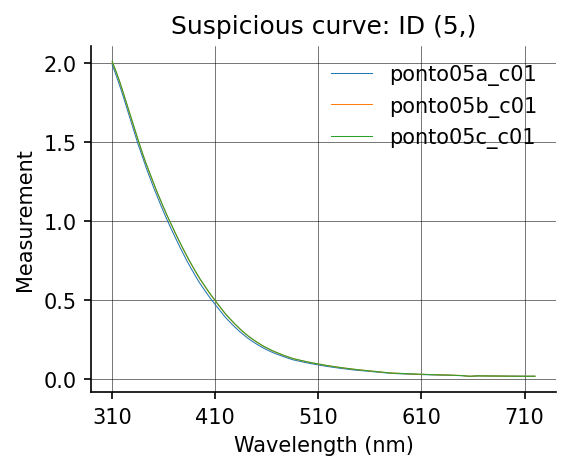

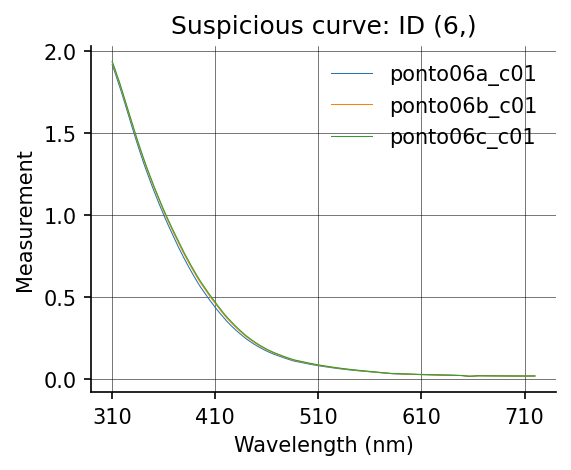

Object Spectra with 21 observations and 411 wavelengths


In [34]:
spectra = spectra.consistency.check(
    std_threshold=0.01,
    measurements='sample',
    groupby='id',
    remove_suspicious=True,
    plot_suspicious=True,
    recursive=True,
    dpi=150
    )
print(spectra)

The plots above show the curves in which the standard deviation is higher than the threshold.

#### **Retrieve absorption**

## Retrieve CDOM absorption

After reviewing the input and replicate consistency, apply the salinity-specific blank curves and the 600 nm null-point correction. The path length is 0.1071 m for this setup.

In [35]:
spectra.cdom.compute_absorption(
    blank=salinity_curves,
    wl_null_point_correction=600,
    pathlength=0.1071,
)
assert spectra.absorption is not None

Blank correction will be applied with provided salinity curves
Using wavelength range 310-720 nm for CDOM processing


A large null-point offset triggers a quality-control warning. Review `spectra.npc_offset` and the corrected curves before using the results.

## Fit the exponential CDOM model

The fit returns the absorption at 443 nm and the exponential slope over 350Ã¢â‚¬â€œ500 nm.

In [36]:
spectra.cdom.expfit(wl_ref=443, wl_range=(350, 500))
assert spectra.cdom_fitted is not None
spectra.cdom_fitted

,a443,slope_350_500
id,,
1,0.340533,0.019510
2,0.622568,0.018189
3,0.871642,0.017254
4,3.253265,0.016781
5,6.217078,0.015775
6,5.854108,0.015924


The fitted model is:

$$
a_\mathrm{CDOM}(\lambda) = a_\mathrm{CDOM}(443) e^{-S(\lambda-443)}
$$

The fitted parameters are stored in `spectra.cdom_fitted`.

## Visualize the processed spectra

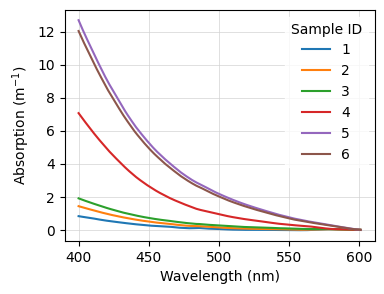

In [37]:
assert spectra.absorption is not None
fig, ax = plt.subplots(figsize=(4, 3), dpi=100)
spectra.absorption.loc[:, 400:601].transpose().plot(ax=ax)
ax.set(xlabel='Wavelength (nm)', ylabel='Absorption (m$^{-1}$)')
ax.grid(which='both', axis='both', color='lightgrey', lw=0.5)
ax.legend(frameon=True, title='Sample ID', edgecolor='white')
plt.show()
plt.close(fig)

And save the fitted parameters:

In [ ]:
assert spectra.cdom_fitted is not None
output_path = data_dir / 'fitted_cdom.csv'
spectra.cdom_fitted.to_csv(output_path, sep=';', index=True)
print(f'Saved fitted parameters to: {output_path}')